In [3]:
import importlib
import torch
import helper_lib.data_loader as data_module
importlib.reload(data_module)
import helper_lib.model as model_module


In [2]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

train_loader = data_module.get_assignment4_data_loader(
    train=True
)
test_loader = data_module.get_assignment4_data_loader(
    train=False
)

images, labels = next(iter(train_loader))

print("Device:", device)
print("Training images:", len(train_loader.dataset))
print("Test images:", len(test_loader.dataset))
print("Batch shape:", images.shape)
print("Pixel range:", images.min().item(), images.max().item())

Device: mps
Training images: 50000
Test images: 10000
Batch shape: torch.Size([32, 3, 32, 32])
Pixel range: 0.0 1.0


In [4]:
importlib.reload(model_module)

cifar_diffusion = model_module.DiffusionModel(
    model=model_module.UNet(
        image_size=32,
        num_channels=3
    ),
    schedule_fn=model_module.offset_cosine_diffusion_schedule
).to(device)
cifar_diffusion.eval()

with torch.no_grad():
    test_images = images[:2].to(device)
    noise_variances = torch.full(
        (2, 1, 1, 1),
        0.5,
        device=device
    )

    predictions = cifar_diffusion.network(
        test_images,
        noise_variances
    )

print("Output shape:", predictions.shape)
print("All finite:", torch.isfinite(predictions).all().item())

Output shape: torch.Size([2, 3, 32, 32])
All finite: True


In [5]:
import helper_lib.trainer as trainer_module

importlib.reload(trainer_module)

pixel_sum = 0.0
pixel_square_sum = 0.0
pixel_count = 0

for batch_images, _ in train_loader:
    pixel_sum += batch_images.sum().item()
    pixel_square_sum += batch_images.square().sum().item()
    pixel_count += batch_images.numel()

cifar_mean = pixel_sum / pixel_count
cifar_std = max(
    pixel_square_sum / pixel_count - cifar_mean ** 2,
    1e-8
) ** 0.5

cifar_diffusion.set_normalizer(cifar_mean, cifar_std)

criterion = torch.nn.MSELoss()

optimizer = torch.optim.Adam(
    cifar_diffusion.network.parameters(),
    lr=1e-4
)

print(f"Mean: {cifar_mean:.4f}, std: {cifar_std:.4f}")

cifar_diffusion = trainer_module.train_diffusion(
    model=cifar_diffusion,
    data_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=1
)

Mean: 0.4734, std: 0.2516
Debug - Loss: 0.3918, Noise std: 1.0030, Pred std: 0.7233
Signal rates range: 0.0226-0.9439
Noise rates range: 0.3304-0.9997
Debug - Loss: 0.3468, Noise std: 1.0012, Pred std: 0.7956
Signal rates range: 0.0220-0.9082
Noise rates range: 0.4185-0.9998
Gradient norm: 1.5027
Debug - Loss: 0.3398, Noise std: 0.9980, Pred std: 0.7392
Signal rates range: 0.0319-0.9432
Noise rates range: 0.3322-0.9995
Gradient norm: 1.7876
Debug - Loss: 0.2058, Noise std: 0.9989, Pred std: 0.8110
Signal rates range: 0.0201-0.9357
Noise rates range: 0.3527-0.9998
Gradient norm: 1.3515
Gradient norm: 0.5952
Gradient norm: 1.0530
Gradient norm: 0.7315
Debug - Loss: 0.1213, Noise std: 1.0045, Pred std: 0.9146
Signal rates range: 0.0473-0.9356
Noise rates range: 0.3531-0.9989
Debug - Loss: 0.0993, Noise std: 1.0003, Pred std: 0.9334
Signal rates range: 0.0218-0.9244
Noise rates range: 0.3814-0.9998
Gradient norm: 0.4752
Gradient norm: 0.2387
Debug - Loss: 0.1269, Noise std: 1.0018, Pred st

Generation Step 0/100: t=1.000
  Current images std: 0.9974
  Pred images std: 6.3716
  Signal rate: 0.0200, Noise rate: 0.9998
Generation Step 25/100: t=0.750
  Current images std: 1.3556
  Pred images std: 2.1876
  Signal rate: 0.3224, Noise rate: 0.9466
Generation Step 50/100: t=0.500
  Current images std: 1.7285
  Pred images std: 2.2338
  Signal rate: 0.5945, Noise rate: 0.8041
Generation Step 75/100: t=0.250
  Current images std: 2.0536
  Pred images std: 2.2773
  Signal rate: 0.8105, Noise rate: 0.5858


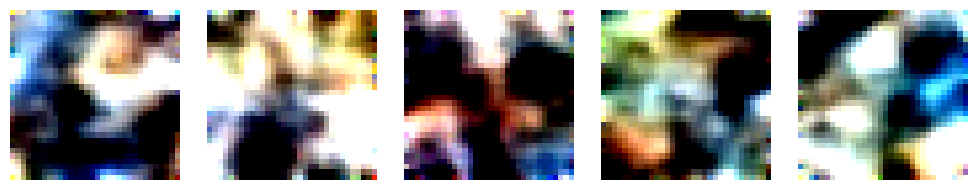

Generated shape: torch.Size([5, 3, 32, 32])
All finite: True


In [6]:
import helper_lib.generator as generator_module

importlib.reload(generator_module)

cifar_samples = generator_module.generate_samples(
    model=cifar_diffusion,
    device=device,
    num_samples=5,
    diffusion_steps=100
)

print("Generated shape:", cifar_samples.shape)
print("All finite:", torch.isfinite(cifar_samples).all().item())

In [7]:
from pathlib import Path

save_path = Path("models/assignment4_cifar10_diffusion.pth")
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": cifar_diffusion.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "normalizer_mean": cifar_diffusion.normalizer_mean,
        "normalizer_std": cifar_diffusion.normalizer_std,
        "image_size": 32,
        "num_channels": 3,
        "schedule": "offset_cosine",
        "epochs": 1
    },
    save_path
)

print("Saved:", save_path.resolve())

Saved: /Users/lisatang/Desktop/5560/sps_genai/models/assignment4_cifar10_diffusion.pth


In [8]:
import helper_lib.assignment4_ebm as ebm_module

importlib.reload(ebm_module)

energy_model = ebm_module.EnergyModel().to(device)
images, _ = next(iter(train_loader))
ebm_images = images[:4].to(device) * 2 - 1

with torch.no_grad():
    energies = energy_model(ebm_images)

print("Input shape:", ebm_images.shape)
print("Energy shape:", energies.shape)
print("All finite:", torch.isfinite(energies).all().item())

Input shape: torch.Size([4, 3, 32, 32])
Energy shape: torch.Size([4, 1])
All finite: True


In [9]:
importlib.reload(ebm_module)

initial_images = torch.rand(
    4, 3, 32, 32, device=device
) * 2 - 1

with torch.no_grad():
    energy_before = energy_model(initial_images).mean().item()

sampled_images = ebm_module.langevin_sample(
    model=energy_model,
    initial_images=initial_images,
    steps=20,
    step_size=10.0,
    noise_std=0.0
)

with torch.no_grad():
    energy_after = energy_model(sampled_images).mean().item()

print("Energy before:", energy_before)
print("Energy after:", energy_after)
print("Sample shape:", sampled_images.shape)
print("All finite:", torch.isfinite(sampled_images).all().item())
print("Samples detached:", not sampled_images.requires_grad)
print(
    "Model gradients restored:",
    all(p.requires_grad for p in energy_model.parameters())
)

Energy before: 0.06825044006109238
Energy after: 0.06810552626848221
Sample shape: torch.Size([4, 3, 32, 32])
All finite: True
Samples detached: True
Model gradients restored: True


In [10]:
importlib.reload(ebm_module)

ebm_optimizer = torch.optim.Adam(
    energy_model.parameters(),
    lr=1e-4,
    betas=(0.0, 0.999)
)

energy_model = ebm_module.train_ebm(
    model=energy_model,
    data_loader=train_loader,
    optimizer=ebm_optimizer,
    device=device,
    epochs=1,
    sampling_steps=60
)

Epoch 1/1 | Batch 100/1563 | Loss: -0.0313 | Real E: -0.0547 | Fake E: -0.0171
Epoch 1/1 | Batch 200/1563 | Loss: -0.0436 | Real E: -0.1724 | Fake E: -0.1049
Epoch 1/1 | Batch 300/1563 | Loss: -0.0339 | Real E: -0.1463 | Fake E: -0.0910
Epoch 1/1 | Batch 400/1563 | Loss: -0.0257 | Real E: -0.1101 | Fake E: -0.0663
Epoch 1/1 | Batch 500/1563 | Loss: -0.0208 | Real E: -0.0850 | Fake E: -0.0486
Epoch 1/1 | Batch 600/1563 | Loss: -0.0168 | Real E: -0.0664 | Fake E: -0.0363
Epoch 1/1 | Batch 700/1563 | Loss: -0.0145 | Real E: -0.0540 | Fake E: -0.0278
Epoch 1/1 | Batch 800/1563 | Loss: -0.0126 | Real E: -0.0448 | Fake E: -0.0218
Epoch 1/1 | Batch 900/1563 | Loss: -0.0112 | Real E: -0.0381 | Fake E: -0.0176
Epoch 1/1 | Batch 1000/1563 | Loss: -0.0102 | Real E: -0.0335 | Fake E: -0.0149
Epoch 1/1 | Batch 1100/1563 | Loss: -0.0092 | Real E: -0.0300 | Fake E: -0.0131
Epoch 1/1 | Batch 1200/1563 | Loss: -0.0084 | Real E: -0.0275 | Fake E: -0.0119
Epoch 1/1 | Batch 1300/1563 | Loss: -0.0075 | Rea

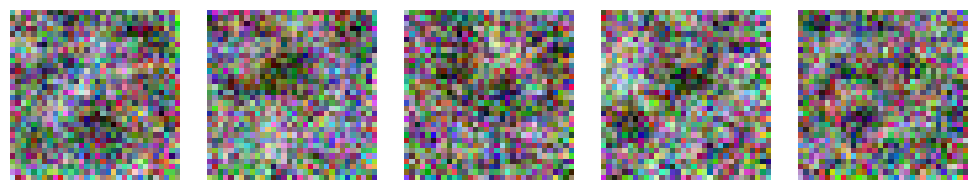

Energy before: 0.7384913563728333
Energy after: 0.04303853586316109
Generated shape: torch.Size([5, 3, 32, 32])
All finite: True


In [11]:
import matplotlib.pyplot as plt

torch.manual_seed(42)

initial_noise = torch.rand(
    5, 3, 32, 32, device=device
) * 2 - 1

with torch.no_grad():
    energy_before = energy_model(initial_noise).mean().item()

ebm_samples = ebm_module.langevin_sample(
    model=energy_model,
    initial_images=initial_noise,
    steps=100,
    step_size=10.0,
    noise_std=0.005
)

with torch.no_grad():
    energy_after = energy_model(ebm_samples).mean().item()

display_images = (
    (ebm_samples.cpu() + 1) / 2
).clamp(0, 1)

fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for ax, image in zip(axes, display_images):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Energy before:", energy_before)
print("Energy after:", energy_after)
print("Generated shape:", ebm_samples.shape)
print("All finite:", torch.isfinite(ebm_samples).all().item())

In [12]:
from pathlib import Path

save_path = Path("models/assignment4_cifar10_ebm.pth")
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": energy_model.state_dict(),
        "optimizer_state_dict": ebm_optimizer.state_dict(),
        "image_size": 32,
        "num_channels": 3,
        "pixel_range": [-1.0, 1.0],
        "epochs": 1,
        "sampling_steps": 100,
        "step_size": 10.0,
        "noise_std": 0.005
    },
    save_path
)

print("Saved:", save_path.resolve())

Saved: /Users/lisatang/Desktop/5560/sps_genai/models/assignment4_cifar10_ebm.pth


In [13]:
import math

embedding = []

for i in range(4):
    angle = 1 / (10000 ** (2 * i / 8))
    embedding.extend([math.sin(angle), math.cos(angle)])

print([round(value, 6) for value in embedding])

[0.841471, 0.540302, 0.099833, 0.995004, 0.01, 0.99995, 0.001, 1.0]


In [15]:
import torch

x = torch.tensor([2.0], requires_grad=True)
y = x**2 + 3 * x

y.backward()
# Q6(a)
print("x.grad =", x.grad)


x.grad = tensor([7.])


In [17]:
# Q6(b):
x = torch.tensor([2.0], requires_grad=False)
y = x**2 + 3 * x

print("y.requires_grad:", y.requires_grad)

try:
    y.backward()
except RuntimeError as error:
    print("Backward error:", error)

print("x.grad:", x.grad)

# Q6(c): 
x_default = torch.tensor([2.0])
print("Default requires_grad:", x_default.requires_grad)

y.requires_grad: False
Backward error: element 0 of tensors does not require grad and does not have a grad_fn
x.grad: None
Default requires_grad: False


In [18]:
#Q7:
x = torch.tensor([2.0], requires_grad=True)
w = torch.tensor([1.0, 3.0])

y = w[0] * x**2 + w[1] * x
y.backward()

print("x.grad =", x.grad)
print("w.grad =", w.grad)

x.grad = tensor([7.])
w.grad = None


In [19]:
x = torch.tensor([2.0], requires_grad=True)
w = torch.tensor([1.0, 3.0], requires_grad=True)

y = w[0] * x**2 + w[1] * x
y.backward()

print("x.grad =", x.grad)
print("w.grad =", w.grad)

x.grad = tensor([7.])
w.grad = tensor([4., 2.])


In [20]:
x_default = torch.tensor([2.0])
print("Default requires_grad:", x_default.requires_grad)

Default requires_grad: False


In [21]:
#Q8:
x = torch.tensor([1.0], requires_grad=True)
y = x * 3
z = y.detach()
w = z * 2

try:
    w.backward()
except RuntimeError as error:
    print("Error:", error)

print("x.grad =", x.grad)

Error: element 0 of tensors does not require grad and does not have a grad_fn
x.grad = None


In [22]:
#Q8:
x = torch.tensor([1.0], requires_grad=True)
y = x * 3
z = y.clone()
w = z * 2

try:
    w.backward()
except RuntimeError as error:
    print("Error:", error)

print("x.grad =", x.grad)

x.grad = tensor([6.])


In [23]:
#Q9:
x = torch.tensor([1.0], requires_grad=True)

y1 = x * 2
y1.backward()
print("After first backward:", x.grad)

y2 = x * 3
y2.backward()
print("After second backward:", x.grad)

After first backward: tensor([2.])
After second backward: tensor([5.])


In [24]:
x = torch.tensor([1.0], requires_grad=True)

y1 = x * 2
y1.backward()
print("After first backward:", x.grad)

x.grad.zero_()

y2 = x * 3
y2.backward()
print("After clearing:", x.grad)

After first backward: tensor([2.])
After clearing: tensor([3.])
